In [1]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

RAW_DIR = Path("../data/raw")
PROCESSED_DIR = Path("../data/processed")

sns.set_theme(style="whitegrid")

print("EDA environment ready!")

EDA environment ready!


In [2]:
cv_df = pd.read_csv(PROCESSED_DIR / "cv_processed.csv")
job_df = pd.read_csv(PROCESSED_DIR / "job_processed.csv")
matches_df = pd.read_csv(RAW_DIR / "matches.csv")

print("CV shape:", cv_df.shape)
print("Job shape:", job_df.shape)
print("Matches shape:", matches_df.shape)

CV shape: (9544, 8)
Job shape: (1167, 8)
Matches shape: (122560, 13)


In [3]:
cv_df["skills_list"] = cv_df["skills_list"].apply(json.loads)
job_df["skills_list"] = job_df["skills_list"].apply(json.loads)

all_cv_skills = [
    skill
    for skills in cv_df["skills_list"]
    for skill in skills
]

all_job_skills = [
    skill
    for skills in job_df["skills_list"]
    for skill in skills
]

print("Total CV skill entries:", len(all_cv_skills))
print("Unique CV skills:", len(set(all_cv_skills)))

print("Total Job skill entries:", len(all_job_skills))
print("Unique Job skills:", len(set(all_job_skills)))

Total CV skill entries: 271740
Unique CV skills: 3814
Total Job skill entries: 16038
Unique Job skills: 4950


python                         3900
machine learning               3696
sql                            2063
data analysis                  1792
java                           1710
deep learning                  1596
excel                          1438
autocad                        1432
sales                          1212
data science                   1092
c++                            1092
natural language processing    1092
project management             1064
data analytics                 1036
artificial intelligence         980
Name: count, dtype: int64


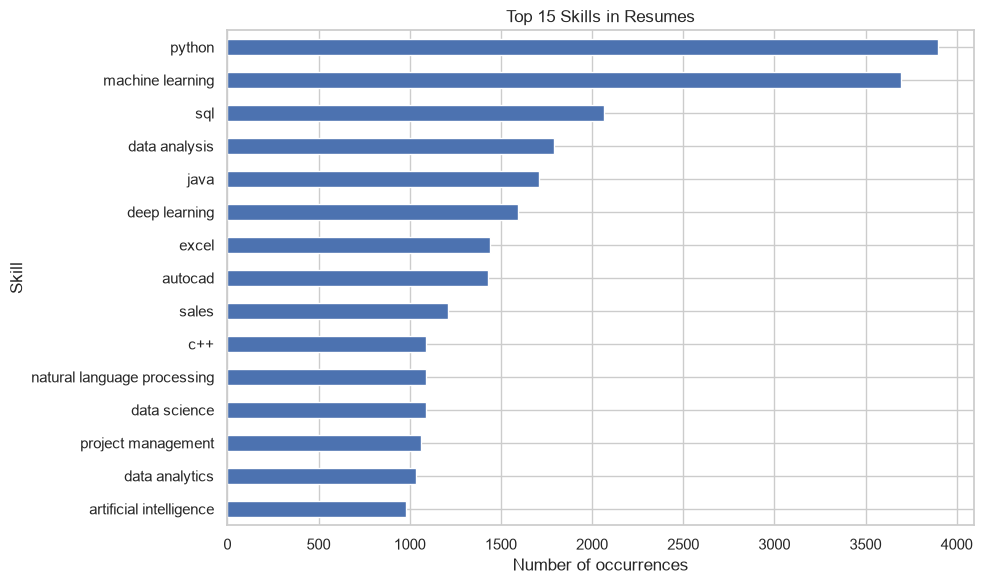

In [4]:
cv_skill_counts = pd.Series(all_cv_skills).value_counts()

print(cv_skill_counts.head(15))

cv_skill_counts.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 15 Skills in Resumes"
)

plt.xlabel("Number of occurrences")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

adaptability             588
relationship building    267
attention to detail      253
data analysis            251
project management       234
negotiation              157
sales                    148
presentation skills      144
business development     137
financial analysis       131
strategic thinking       127
team collaboration       107
self-motivation          105
employee relations       103
financial reporting       95
Name: count, dtype: int64


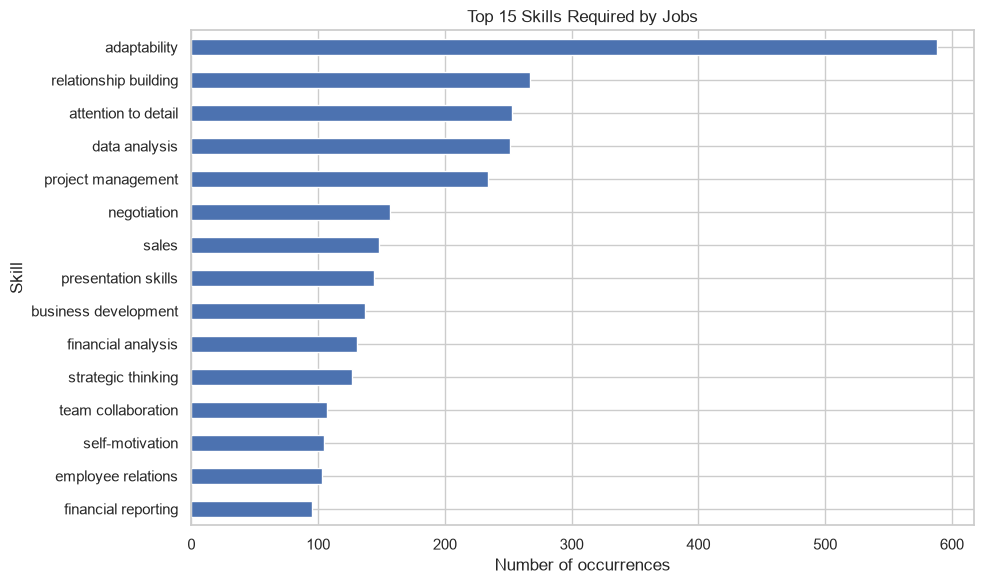

In [5]:
job_skill_counts = pd.Series(all_job_skills).value_counts()

print(job_skill_counts.head(15))

job_skill_counts.head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 15 Skills Required by Jobs"
)

plt.xlabel("Number of occurrences")
plt.ylabel("Skill")
plt.tight_layout()
plt.show()

Unique job categories: 5

Jobs per category:
category
INFORMATION-TECHNOLOGY    240
BUSINESS-DEVELOPMENT      239
FINANCE                   236
SALES                     232
HR                        220
Name: count, dtype: int64


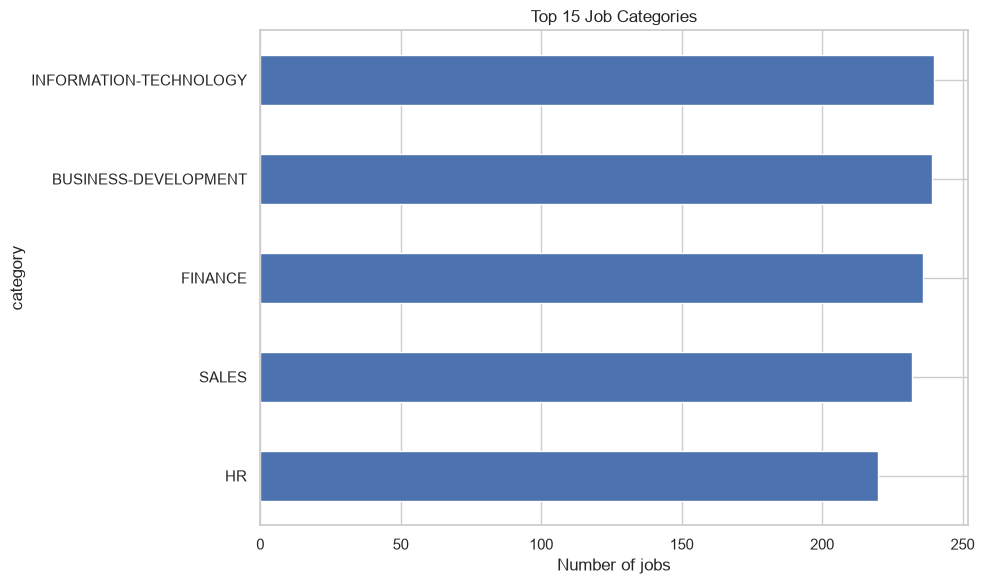

In [6]:
print("Unique job categories:", job_df["category"].nunique())

print("\nJobs per category:")
print(job_df["category"].value_counts().head(20))

job_df["category"].value_counts().head(15).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 15 Job Categories"
)

plt.xlabel("Number of jobs")
plt.tight_layout()
plt.show()

In [7]:
print(cv_df["years_experience"].describe())
print("\nRequired experience:")
print(job_df["years_required"].describe())

count    9544.000000
mean        5.545054
std         4.404667
min         0.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        31.000000
Name: years_experience, dtype: float64

Required experience:
count    1167.000000
mean       14.300951
std        12.626580
min         0.000000
25%         4.000000
50%        10.000000
75%        25.000000
max        40.000000
Name: years_required, dtype: float64


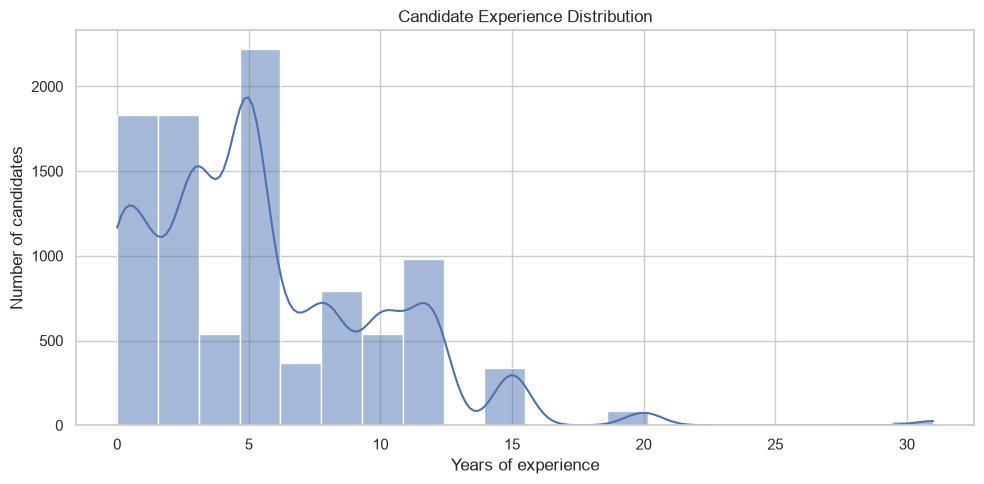

In [8]:
plt.figure(figsize=(10, 5))

sns.histplot(
    cv_df["years_experience"].dropna(),
    bins=20,
    kde=True
)

plt.title("Candidate Experience Distribution")
plt.xlabel("Years of experience")
plt.ylabel("Number of candidates")
plt.tight_layout()
plt.show()

In [9]:
cv_df["resume_length"] = cv_df["resume_text_clean"].str.len()
job_df["job_length"] = job_df["job_description_clean"].str.len()

print("Resume text length:")
print(cv_df["resume_length"].describe())

print("\nJob description length:")
print(job_df["job_length"].describe())

Resume text length:
count    9544.000000
mean     1397.698764
std       449.749483
min       493.000000
25%      1051.000000
50%      1301.000000
75%      1682.000000
max      3000.000000
Name: resume_length, dtype: float64

Job description length:
count     1167.000000
mean      3756.909169
std       2095.137966
min        167.000000
25%       2123.000000
50%       3445.000000
75%       4917.000000
max      13613.000000
Name: job_length, dtype: float64


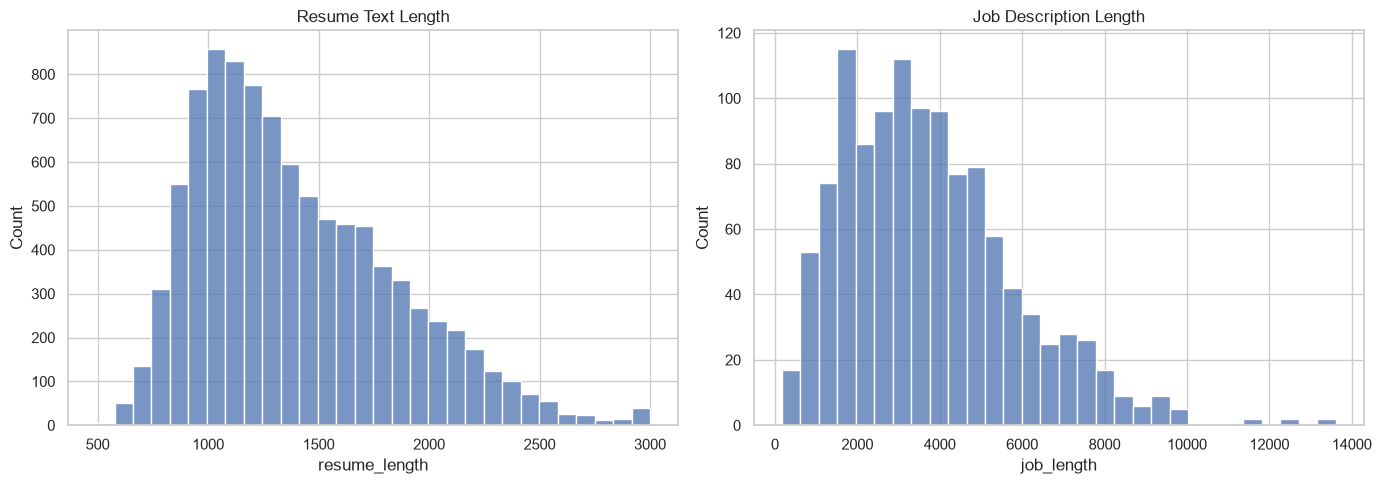

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(cv_df["resume_length"], bins=30, ax=axes[0])
axes[0].set_title("Resume Text Length")

sns.histplot(job_df["job_length"], bins=30, ax=axes[1])
axes[1].set_title("Job Description Length")

plt.tight_layout()
plt.show()

count    122560.000000
mean          0.585740
std           0.036012
min           0.430009
25%           0.564059
50%           0.586842
75%           0.607529
max           0.756099
Name: final_score, dtype: float64


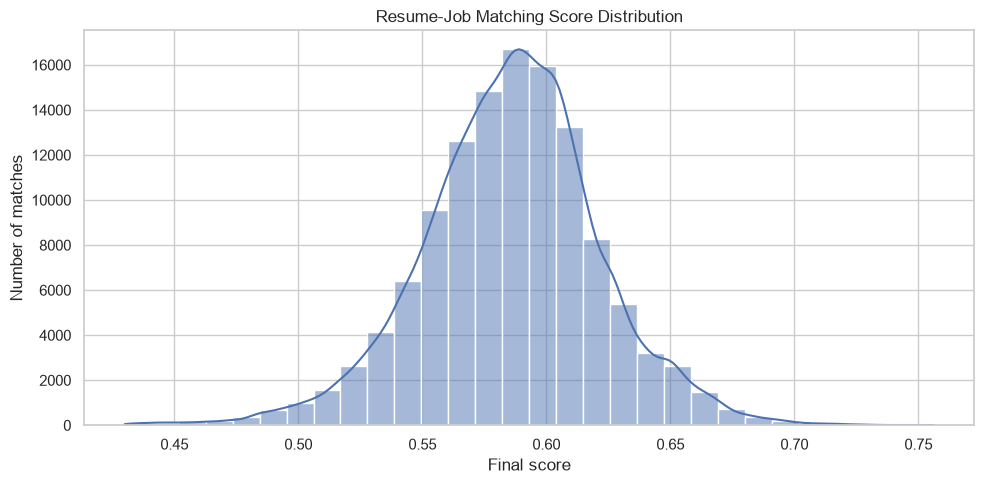

In [11]:
print(matches_df["final_score"].describe())

plt.figure(figsize=(10, 5))

sns.histplot(
    matches_df["final_score"],
    bins=30,
    kde=True
)

plt.title("Resume-Job Matching Score Distribution")
plt.xlabel("Final score")
plt.ylabel("Number of matches")
plt.tight_layout()
plt.show()

In [12]:
print(
    matches_df.groupby("label_strength")["final_score"]
    .agg(["count", "mean", "min", "max"])
)

                 count      mean       min       max
label_strength                                      
medium_positive  70636  0.608124  0.580000  0.679999
strong_positive    774  0.696293  0.680003  0.756099
weak_positive    51150  0.553157  0.430009  0.580000


In [14]:
print("TOP 15 RESUME SKILLS")
print(cv_skill_counts.head(15))

print("\nTOP 15 JOB SKILLS")
print(job_skill_counts.head(15))

print("\nJOB CATEGORY DISTRIBUTION")
print(job_df["category"].value_counts())

TOP 15 RESUME SKILLS
python                         3900
machine learning               3696
sql                            2063
data analysis                  1792
java                           1710
deep learning                  1596
excel                          1438
autocad                        1432
sales                          1212
data science                   1092
c++                            1092
natural language processing    1092
project management             1064
data analytics                 1036
artificial intelligence         980
Name: count, dtype: int64

TOP 15 JOB SKILLS
adaptability             588
relationship building    267
attention to detail      253
data analysis            251
project management       234
negotiation              157
sales                    148
presentation skills      144
business development     137
financial analysis       131
strategic thinking       127
team collaboration       107
self-motivation          105
employee relation

In [15]:
print("=" * 45)
print("      SUMMARY")
print("=" * 45)

print("\n1. SKILLS")
print("Unique CV skills:", len(set(all_cv_skills)))
print("Unique Job skills:", len(set(all_job_skills)))

print("\n2. JOB CATEGORIES")
print("Unique categories:", job_df["category"].nunique())

print("\n3. EXPERIENCE")
print(cv_df["years_experience"].describe())

print("\n4. TEXT LENGTH")
print("Average resume length:", cv_df["resume_length"].mean())
print("Average job length:", job_df["job_length"].mean())

print("\n5. MATCHING SCORES")
print(matches_df["final_score"].describe())

print("\nEDA completed!")

      SUMMARY

1. SKILLS
Unique CV skills: 3814
Unique Job skills: 4950

2. JOB CATEGORIES
Unique categories: 5

3. EXPERIENCE
count    9544.000000
mean        5.545054
std         4.404667
min         0.000000
25%         3.000000
50%         5.000000
75%         8.000000
max        31.000000
Name: years_experience, dtype: float64

4. TEXT LENGTH
Average resume length: 1397.6987636211231
Average job length: 3756.9091688089115

5. MATCHING SCORES
count    122560.000000
mean          0.585740
std           0.036012
min           0.430009
25%           0.564059
50%           0.586842
75%           0.607529
max           0.756099
Name: final_score, dtype: float64

EDA completed!
